# Quickstart: score a stream event by event

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliverHennhoefer/aberrant/blob/main/examples/notebooks/01_quickstart.ipynb)

aberrant detectors see one event at a time. Each event is a `dict[str, float]`.
`score_one` scores the event against everything learned so far, and `learn_one`
updates the detector. There is no training set and no retraining job.

This notebook streams the Shuttle benchmark (49,096 events, about 7% anomalies)
through a scaled Half-Space Trees detector and measures it prequentially:
every event is scored *before* it is learned.

In [ ]:
%pip install --quiet "aberrant[eval]" matplotlib

## Build a detector

`|` chains online preprocessing and a model. Half-Space Trees expects features in `[0, 1]`, so a `MinMaxScaler` goes first.

In [2]:
from aberrant.model.iforest import HalfSpaceTrees
from aberrant.transform import MinMaxScaler

detector = MinMaxScaler() | HalfSpaceTrees(seed=42)
detector

Pipeline(MinMaxScaler(feature_range=(0.0, 1.0)) | HalfSpaceTrees(n_trees=10, height=8, window_size=250, initialized=False))

## Stream a benchmark dataset

The dataset is downloaded and cached on first use. `stream()` yields `(event, label)` pairs; the label is only used for evaluation, never for learning.

In [3]:
from aberrant.stream.dataset import Dataset, load

dataset = load(Dataset.SHUTTLE)
event, label = next(iter(dataset.stream()))
print(event)
print("label:", label)

{'feature_0': 50.0, 'feature_1': 21.0, 'feature_2': 77.0, 'feature_3': 0.0, 'feature_4': 28.0, 'feature_5': 0.0, 'feature_6': 27.0, 'feature_7': 48.0, 'feature_8': 22.0}
label: 1


## Evaluate prequentially

`PrequentialEvaluator` owns the score-before-learn loop. The first 250 learned events are a warm-up: they fill the detector's reference window and are left out of the metrics.

In [4]:
import time

from aberrant.evaluate import PrequentialEvaluator

detector = MinMaxScaler() | HalfSpaceTrees(seed=42)
evaluator = PrequentialEvaluator(
    detector, warmup=250, metrics=True, metric_window_size=None
)

started = time.perf_counter()
records = list(evaluator.iter_evaluate(dataset.stream()))
elapsed = time.perf_counter() - started

result = evaluator.result()
print(f"{len(records):,} events in {elapsed:.1f} s")
print(f"ROC-AUC {result.roc_auc:.3f}, average precision {result.average_precision:.3f}")

49,097 events in 8.8 s
ROC-AUC 0.974, average precision 0.802


## Look at the scores

Anomalies (orange) sit at the top of the score range while the detector keeps learning.

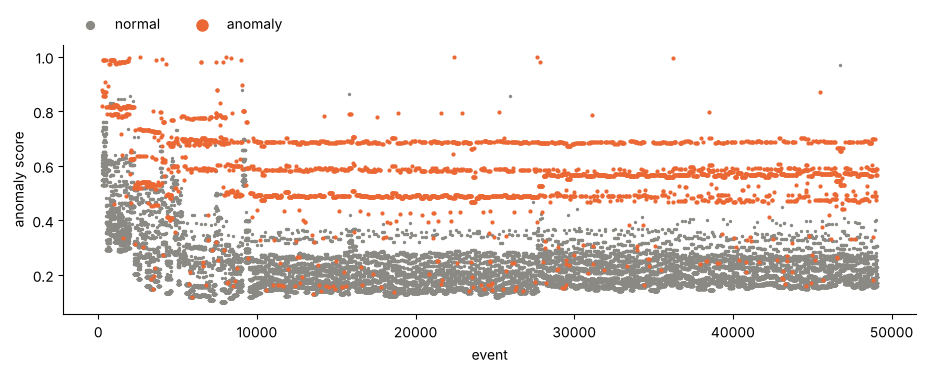

In [5]:
import matplotlib.pyplot as plt
import numpy as np

scored = [(r.index, r.score, int(r.label)) for r in records if r.score is not None]
index, score, label = (np.array(column) for column in zip(*scored, strict=True))

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.scatter(index[label == 0], score[label == 0], s=2, color="#8a8984", label="normal")
ax.scatter(index[label == 1], score[label == 1], s=4, color="#eb6834", label="anomaly")
ax.set_xlabel("event")
ax.set_ylabel("anomaly score")
ax.legend(
    loc="lower left", bbox_to_anchor=(0, 1.0), ncols=2, markerscale=4, frameon=False
)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

## Next steps

- Swap in another detector: see the [model guide](https://oliverhennhoefer.github.io/aberrant/user_guide/models/).
- Turn scores into alerts: [03_scores_to_alerts.ipynb](03_scores_to_alerts.ipynb).
- Score edges in a graph stream: [02_graph_streams.ipynb](02_graph_streams.ipynb).